# 08 — Virtual diagnostic for BCM_GUN

Can we infer the charge `y = BCM_GUN` of a shot from the other measurements `X` of **the same shot**, as if the
BCM stopped working at a certain time?

**Data:** `results/datasets/segment_XX.npz` (made by `scripts/extract_features.py`): per segment, `X` (16 features,
group B already shifted one row so every row is one shot), `y`, and a `valid` flag (not frozen, complete).
Only valid shots are used.

**Test "BCM lost at a certain time"** — per segment, chronologically:
- a cut at fraction `CUT` of the segment: models are trained on the valid shots **before** the cut
- after the cut the BCM is assumed lost: `y` is inferred from that shot's own `X` and compared with the real BCM
- nothing after the cut is used for training (no future leakage)

**Models:** Ridge (linear, standardised features, median-imputed NaN) and gradient-boosted trees
(`HistGradientBoostingRegressor`, handles NaN natively).
**Baselines:** *BCM frozen at cut* (the last BCM reading before the cut is reused for every later shot), *training mean*.

**Scores on the shots after the cut:** RMSE, RMSE relative to the mean charge, and R² (1 = perfect,
0 = as good as predicting the mean of the test period, < 0 = worse).

Segments are trained separately: their charge levels differ by up to ~100× (0.1–10 nC).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASETS = REPO / "results" / "datasets"
OUT = REPO / "results" / "virtual_diagnostic"
OUT.mkdir(parents=True, exist_ok=True)

CUT = 0.7                                  # BCM lost after this fraction of each segment
CUT_SWEEP = [0.5, 0.6, 0.7, 0.8, 0.9]      # other cut times to test
MIN_VALID = 500                            # skip segments with fewer valid shots
SMOOTH = 51                                # rolling mean (shots) for the time-series plots

COLORS = {"Ridge": "#2a78d6", "Gradient boosting": "#eb6834"}
TRUE, MUTED, GRID, INK = "#2b2b29", "#8a8985", "#e6e5e1", "#2b2b29"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])

## Load the datasets

In [2]:
manifest = json.loads((DATASETS / "manifest.json").read_text())
FEATURES = manifest["features"]

segments = {}
for info in manifest["segments"]:
    z = np.load(DATASETS / info["file"])
    segments[info["segment"]] = {"X": z["X"], "y": z["y"], "valid": z["valid"], "run": info["run"],
                                 "chunks": f"{info['first_chunk']}–{info['last_chunk']}"}

overview = pd.DataFrame({
    k: {"run": s["run"].removeprefix("acquisition_"), "chunks": s["chunks"], "shots": len(s["y"]),
        "valid": int(s["valid"].sum()), "BCM mean [nC]": s["y"][s["valid"]].mean(),
        "BCM std / mean": s["y"][s["valid"]].std() / s["y"][s["valid"]].mean(),
        "used": s["valid"].sum() >= MIN_VALID}
    for k, s in segments.items()
}).T.rename_axis("segment")
print(f"target: {manifest['target']} | {len(FEATURES)} features: {FEATURES}")
overview.style.format({"BCM mean [nC]": "{:.3f}", "BCM std / mean": "{:.1%}"})

target: BCM_GUN | 16 features: ['lab_laser_power', 'BTV_intensity', 'PGLA_drop', 'BTV_amplitude', 'PKI15A', 'BTV_mean_x', 'BTV_sigma_major', 'BTV_sigma_minor', 'BTV_tilt', 'BTV_ellipticity', 'SVD_s1', 'SVD_s2', 'SVD_s3', 'SVD_s4', 'SVD_s5', 'SVD_s6']


,run,chunks,shots,valid,BCM mean [nC],BCM std / mean,used
segment,,,,,,,
0,2026-10-07_21-43-26,11–71,6027,4637,0.223,11.9%,True
1,2026-10-08_00-08-19,0–193,19400,16658,4.814,8.7%,True
2,2026-10-08_15-42-27,0–1,200,154,0.145,8.9%,False
3,2026-10-08_15-42-27,4–74,7100,5427,0.122,18.5%,True
4,2026-10-08_15-42-27,76–120,4500,3855,0.101,32.8%,True
5,2026-10-08_21-11-47,0–199,20000,17443,5.468,9.0%,True
6,2026-10-09_07-46-07,0–40,4100,3137,5.504,4.9%,True
7,2026-10-09_07-46-07,87–106,2000,1780,10.097,6.5%,True


## Models, baselines and the cut

In [3]:
def make_models():
    return {
        "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13))),
        "Gradient boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0),
    }


def scores(y, pred):
    err = y - pred
    return {"RMSE": np.sqrt(np.mean(err**2)), "rel RMSE": np.sqrt(np.mean(err**2)) / y.mean(),
            "R²": 1 - np.sum(err**2) / np.sum((y - y.mean()) ** 2)}


def run_cut(seg, cut):
    """Train before the cut, infer after it. Returns predictions on the test shots, scores and fitted models."""
    s = segments[seg]
    n = len(s["y"])
    cut_row = int(cut * n)
    train = s["valid"] & (np.arange(n) < cut_row)
    test = s["valid"] & (np.arange(n) >= cut_row)
    X, y = s["X"], s["y"]

    preds = {"BCM frozen at cut": np.full(test.sum(), y[train][-1]),
             "training mean": np.full(test.sum(), y[train].mean())}
    models = make_models()
    for name, model in models.items():
        model.fit(X[train], y[train])
        preds[name] = model.predict(X[test])
    table = pd.DataFrame({name: scores(y[test], p) for name, p in preds.items()}).T
    return {"train": train, "test": test, "cut_row": cut_row, "preds": preds, "scores": table, "models": models}


used = [k for k in segments if overview.loc[k, "used"]]
results = {k: run_cut(k, CUT) for k in used}

summary = pd.concat({k: r["scores"] for k, r in results.items()}, names=["segment", "method"])
summary.unstack("method")["rel RMSE"].style.format("{:.1%}").set_caption(f"RMSE relative to the mean charge, BCM lost at {CUT:.0%} of each segment")

method,BCM frozen at cut,training mean,Ridge,Gradient boosting
segment,,,,
0,10.2%,17.1%,8.7%,6.4%
1,13.3%,7.4%,4.8%,5.3%
3,20.0%,15.6%,13.2%,12.9%
4,41.3%,20.5%,12.9%,13.2%
5,7.3%,7.4%,2.4%,2.6%
6,7.8%,4.9%,0.9%,1.1%
7,8.7%,8.7%,4.4%,7.2%


In [4]:
summary.unstack("method")["R²"].round(2)

method,BCM frozen at cut,training mean,Ridge,Gradient boosting
segment,,,,
0,-0.26,-2.54,0.08,0.51
1,-2.21,-0.00,0.59,0.50
3,-0.67,-0.01,0.28,0.31
4,-3.09,-0.01,0.60,0.58
5,-0.09,-0.10,0.88,0.86
6,-1.78,-0.11,0.96,0.94
7,-0.00,-0.00,0.74,0.30


## Inferred vs measured charge after the cut

Grey dots: measured BCM (all valid shots). Lines: 51-shot rolling mean of the measured charge (black) and of the
inferred one (colours) after the cut. Dashed: BCM frozen at the cut.

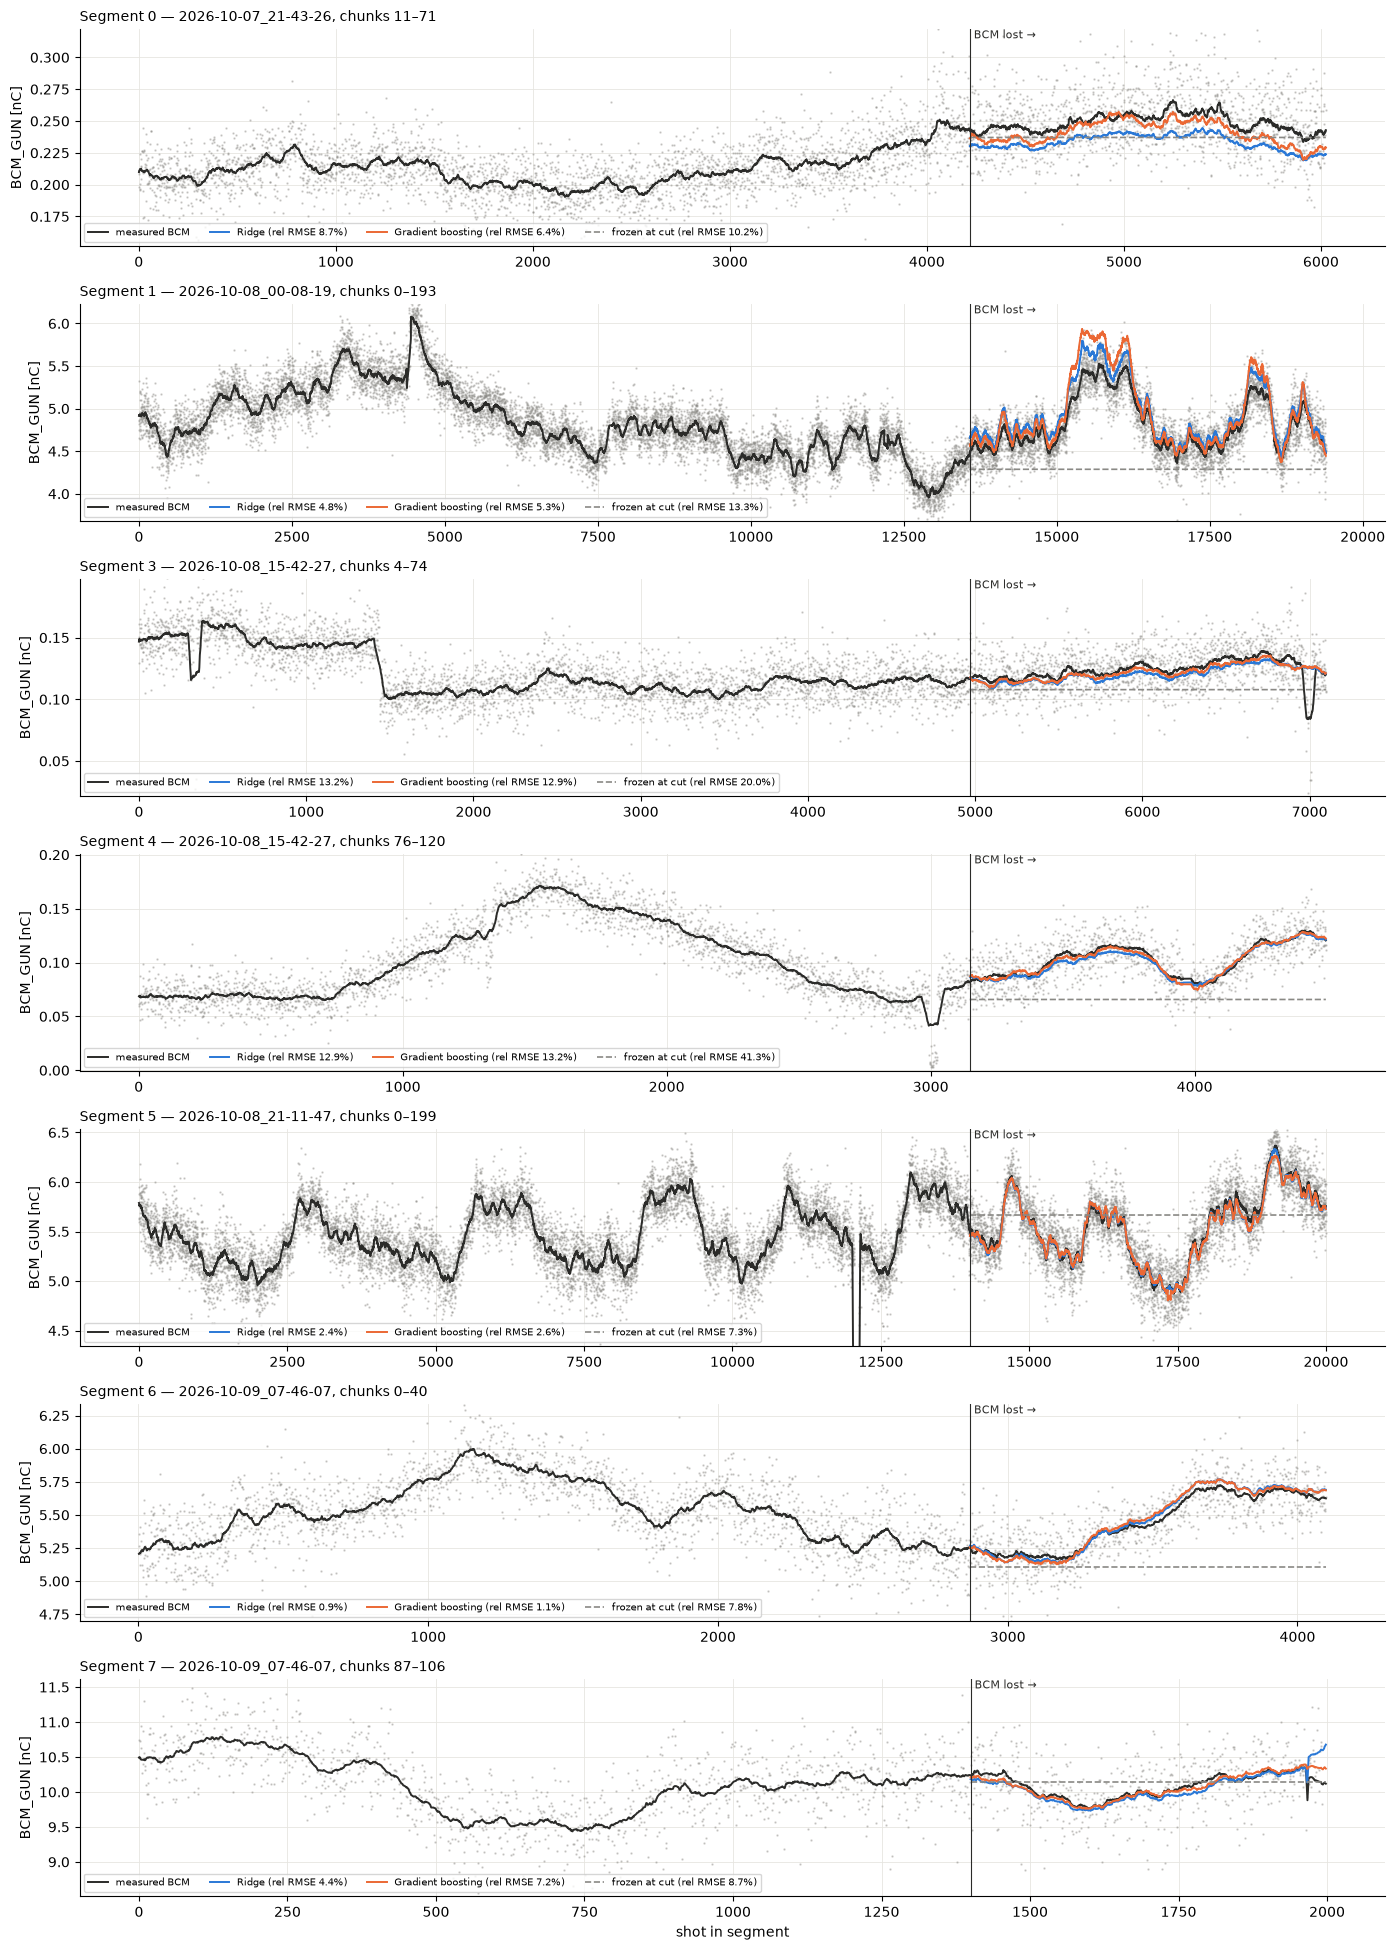

In [5]:
fig, axes = plt.subplots(len(used), 1, figsize=(14, 2.8 * len(used)), squeeze=False)
for ax, k in zip(axes[:, 0], used):
    s, r = segments[k], results[k]
    shot = np.arange(len(s["y"]))
    ax.plot(shot[s["valid"]], s["y"][s["valid"]], ".", ms=1.5, color=MUTED, alpha=0.35)
    smooth = lambda v: pd.Series(v).rolling(SMOOTH, center=True, min_periods=1).mean()
    ax.plot(shot[s["valid"]], smooth(s["y"][s["valid"]]), color=TRUE, lw=1.4, label="measured BCM")
    for name, color in COLORS.items():
        ax.plot(shot[r["test"]], smooth(r["preds"][name]), color=color, lw=1.4,
                label=f"{name} (rel RMSE {r['scores'].loc[name, 'rel RMSE']:.1%})")
    ax.plot(shot[r["test"]], r["preds"]["BCM frozen at cut"], "--", color=MUTED, lw=1.2,
            label=f"frozen at cut (rel RMSE {r['scores'].loc['BCM frozen at cut', 'rel RMSE']:.1%})")
    ax.axvline(r["cut_row"], color=INK, lw=0.8)
    ax.text(r["cut_row"], 1.0, " BCM lost →", transform=ax.get_xaxis_transform(), va="top", fontsize=8, color=INK)
    lo, hi = np.percentile(s["y"][s["valid"]], [0.5, 99.5])
    ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
    ax.set_title(f"Segment {k} — {s['run'].removeprefix('acquisition_')}, chunks {s['chunks']}", fontsize=10, loc="left")
    ax.set_ylabel("BCM_GUN [nC]")
    ax.legend(fontsize=7, loc="lower left", ncol=4)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
axes[-1, 0].set_xlabel("shot in segment")
fig.tight_layout()
fig.savefig(OUT / f"timeseries_cut{int(CUT * 100)}.png", dpi=130, bbox_inches="tight")

## Inferred vs measured, shot by shot (after the cut)

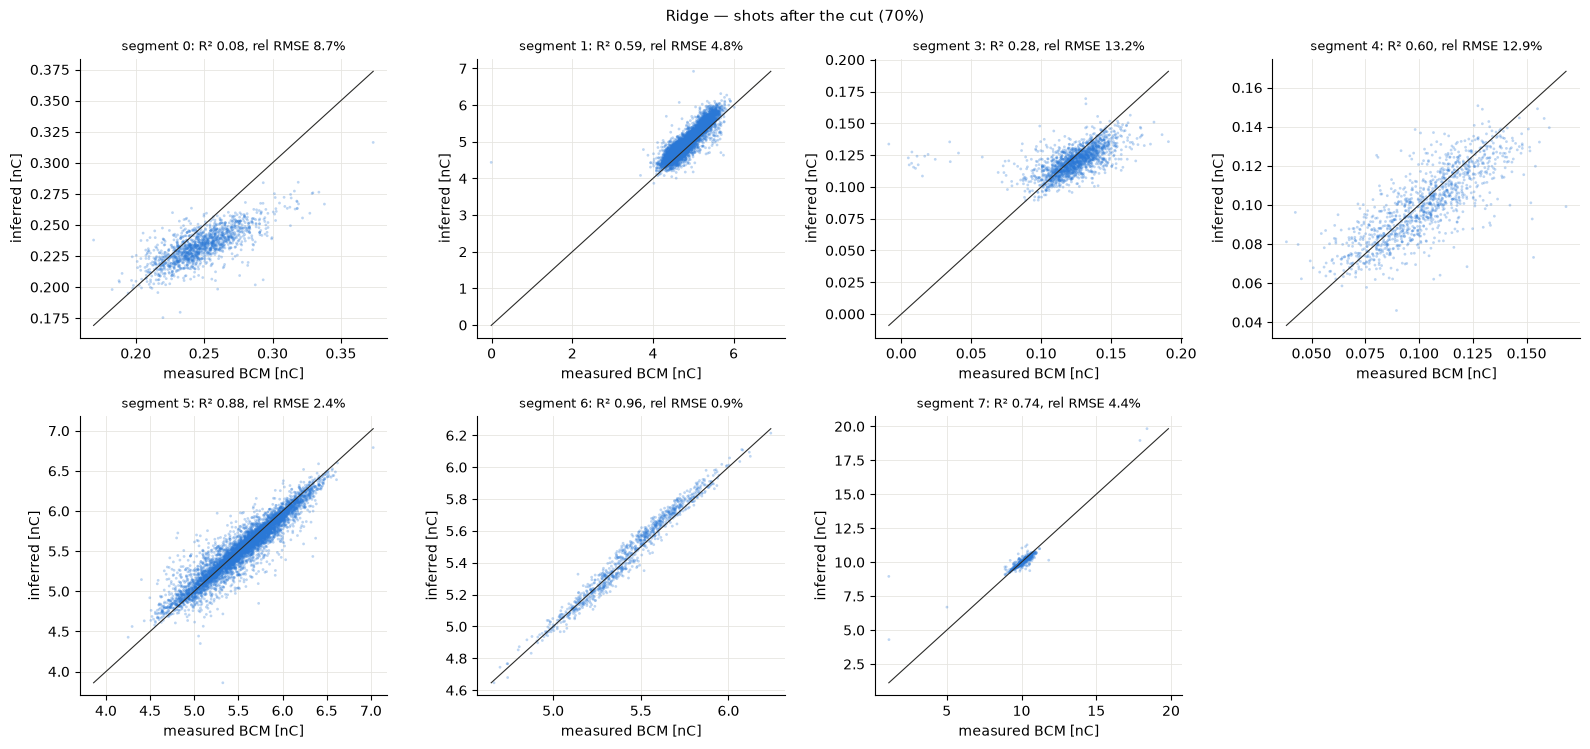

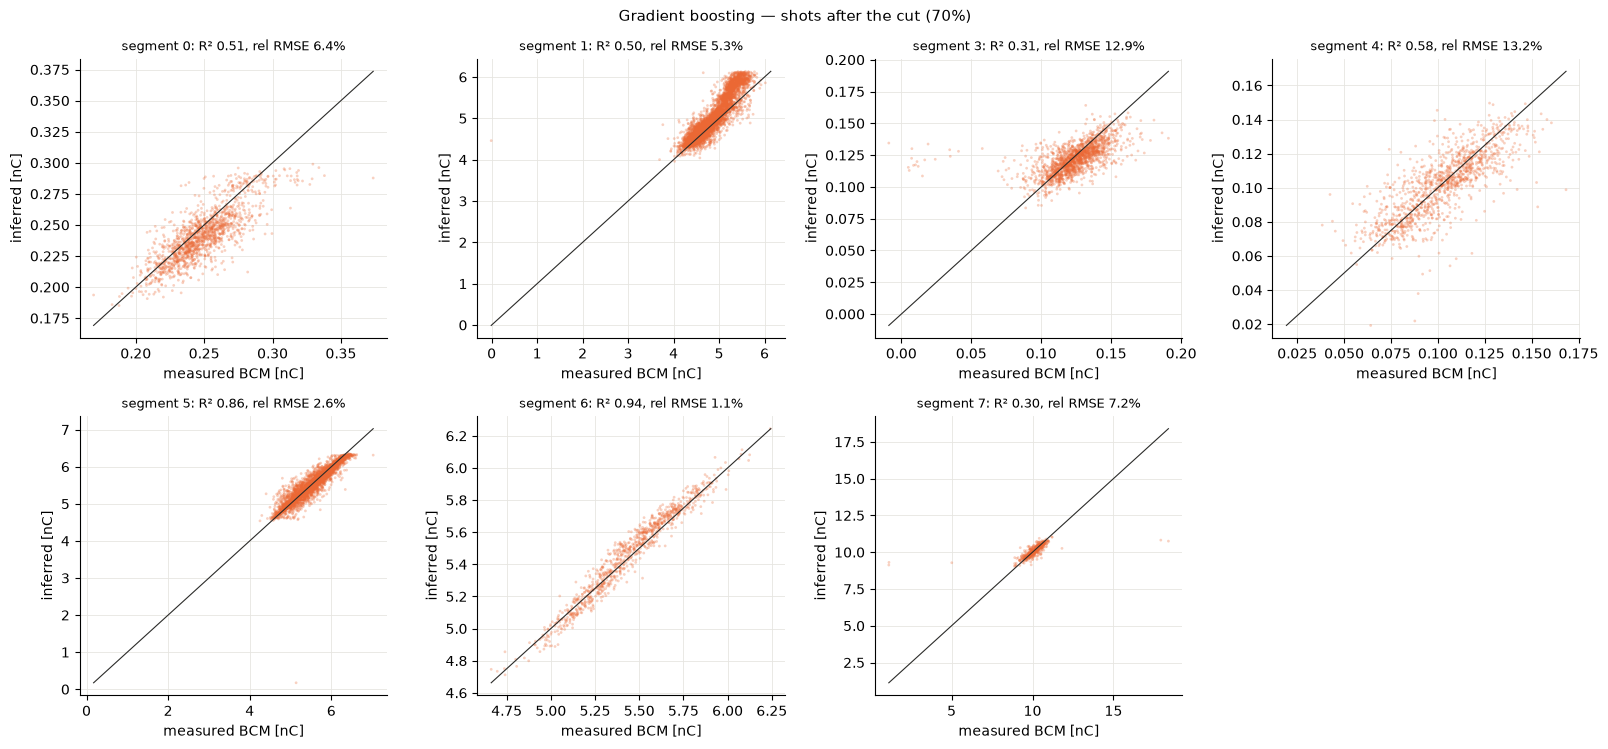

In [6]:
ncols = 4
nrows = int(np.ceil(len(used) / ncols))
for name, color in COLORS.items():
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.8 * nrows), squeeze=False)
    for ax, k in zip(axes.ravel(), used):
        s, r = segments[k], results[k]
        y_test, p = s["y"][r["test"]], r["preds"][name]
        ax.scatter(y_test, p, s=4, color=color, alpha=0.3, edgecolors="none")
        lim = [min(y_test.min(), p.min()), max(y_test.max(), p.max())]
        ax.plot(lim, lim, color=INK, lw=0.8)
        ax.set(title=f"segment {k}: R² {r['scores'].loc[name, 'R²']:.2f}, rel RMSE {r['scores'].loc[name, 'rel RMSE']:.1%}",
               xlabel="measured BCM [nC]", ylabel="inferred [nC]")
        ax.title.set_fontsize(9)
        ax.grid(color=GRID, lw=0.6)
        ax.set_axisbelow(True)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    for ax in axes.ravel()[len(used):]:
        ax.set_visible(False)
    fig.suptitle(f"{name} — shots after the cut ({CUT:.0%})", fontsize=11)
    fig.tight_layout()
    fig.savefig(OUT / f"scatter_{name.replace(' ', '_').lower()}_cut{int(CUT * 100)}.png", dpi=130, bbox_inches="tight")

## Does it depend on when the BCM is lost?

Same test for several cut times. A later cut means more training data but a shorter (and different) test period.

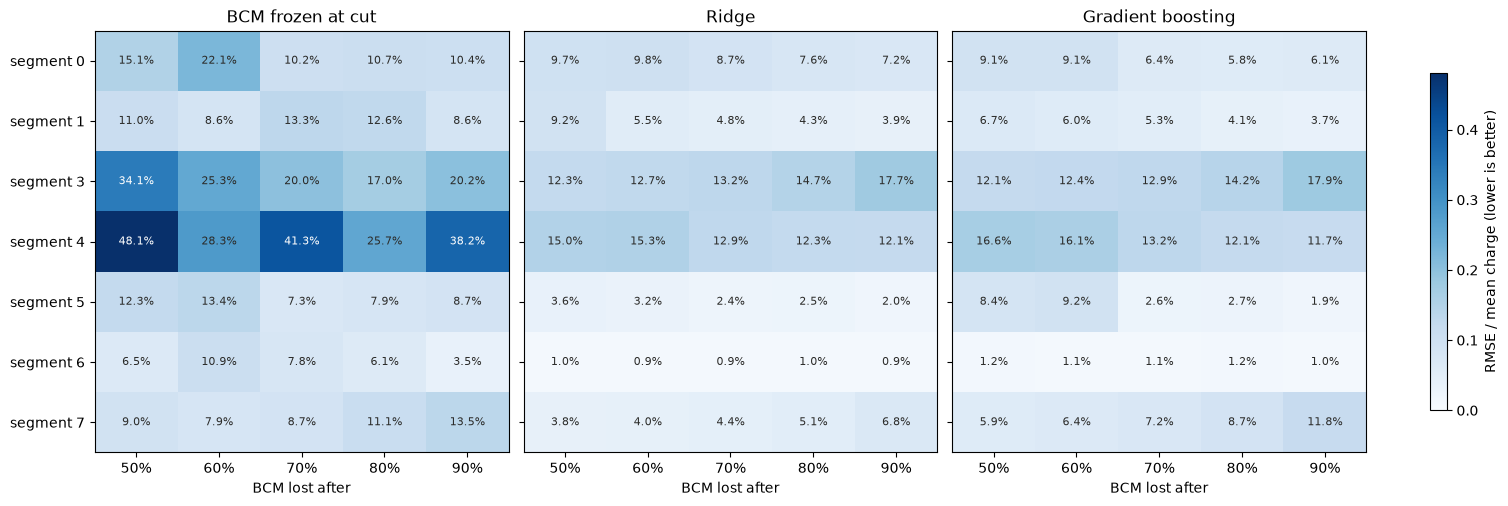

In [7]:
sweep = {(k, cut): run_cut(k, cut)["scores"] for k in used for cut in CUT_SWEEP}
sweep = pd.concat(sweep, names=["segment", "cut", "method"])["rel RMSE"].unstack("cut")

methods = ["BCM frozen at cut", "Ridge", "Gradient boosting"]
vmax = sweep.loc[(slice(None), methods), :].max().max()
fig, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 0.45 * len(used) + 1.8), sharey=True, layout="constrained")
for ax, m in zip(axes, methods):
    table = sweep.xs(m, level="method")
    im = ax.imshow(table, cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(table.to_numpy()):
        ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 * vmax else INK)
    ax.set_xticks(range(len(CUT_SWEEP)), [f"{c:.0%}" for c in CUT_SWEEP])
    ax.set_yticks(range(len(table)), [f"segment {k}" for k in table.index])
    ax.set(title=m, xlabel="BCM lost after")
fig.colorbar(im, ax=axes, shrink=0.8, label="RMSE / mean charge (lower is better)")
fig.savefig(OUT / "cut_sweep.png", dpi=130, bbox_inches="tight");

## Which features does the inference use?

Permutation importance on the shots after the cut: how much the RMSE grows when one feature is shuffled,
relative to the RMSE with all features (gradient boosting).

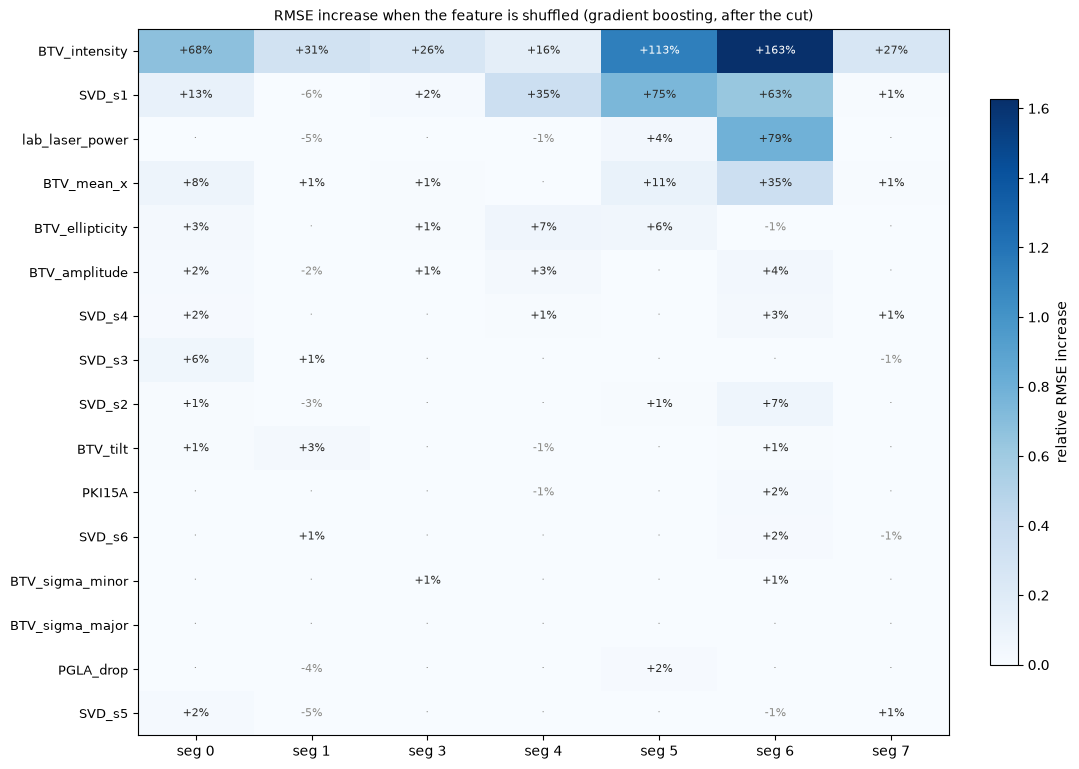

In [8]:
importance = {}
for k in used:
    s, r = segments[k], results[k]
    model = r["models"]["Gradient boosting"]
    pi = permutation_importance(model, s["X"][r["test"]], s["y"][r["test"]], n_repeats=5, random_state=0,
                                scoring="neg_root_mean_squared_error")
    importance[k] = pi.importances_mean / r["scores"].loc["Gradient boosting", "RMSE"]
importance = pd.DataFrame(importance, index=FEATURES)
importance = importance.loc[importance.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(1.1 * len(used) + 3, 0.38 * len(FEATURES) + 1.5), layout="constrained")
vmax = max(importance.to_numpy().max(), 0.05)
im = ax.imshow(importance.clip(lower=0), cmap="Blues", vmin=0, vmax=vmax, aspect="auto")
for (i, j), v in np.ndenumerate(importance.to_numpy()):
    ax.text(j, i, f"{v:+.0%}" if abs(v) >= 0.005 else "·", ha="center", va="center", fontsize=8,
            color="white" if v > 0.6 * vmax else (INK if v >= 0.005 else MUTED))
ax.set_xticks(range(len(used)), [f"seg {k}" for k in used])
ax.set_yticks(range(len(FEATURES)), importance.index, fontsize=9)
ax.set_title("RMSE increase when the feature is shuffled (gradient boosting, after the cut)", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, label="relative RMSE increase")
fig.savefig(OUT / "feature_importance.png", dpi=130, bbox_inches="tight");